# Validating the ordeal axis on Guardian news

This notebook tests whether a single direction in a word embedding separates news about ordeals from news about natural dangers.

1. **Data.** Collects 500 Guardian articles for each of three groups (ordeal, natural danger, and a control group of unrelated topics) and rates a blind sample of 90 by hand, to check that the groups contain what they should.
2. **Embedding.** Loads the pretrained Google News word2vec vectors, normalizes them to unit length and tokenizes the articles.
3. **Axis and scoring.** Builds the ordeal axis, scores every article on it, tests whether ordeal articles score higher than natural danger articles, and examines which words drive the scores.

In [39]:
%pip install -q gensim numpy pandas requests matplotlib

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 1. Collecting the Guardian articles

The articles come from the Guardian Open Platform API, which offers a catalogue of subject tags (such as `uk/murder`) and a search over articles by tag and date. The next cell sets up access to the API, with at most one request per second and every response stored on disk so that it is downloaded only once, and prints the number of items available.

In [40]:
import os
import time
import hashlib
import json
import random
from collections import Counter
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt

GUARDIAN_KEY = os.environ.get("GUARDIAN_API_KEY")  # only needed for calls not in the cache


API = "https://content.guardianapis.com"
GUARDIAN_DIR = Path("data") / "guardian"
CACHE_DIR = GUARDIAN_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

GROUP_COLORS = {"ordeal": "#2a78d6", "natural": "#eb6834"}

_last_call = 0.0


def guardian_get(endpoint, params):
    """GET an Open Platform endpoint and return its "response" object, cached on disk."""
    global _last_call
    key = hashlib.md5(json.dumps([endpoint, params], sort_keys=True).encode()).hexdigest()
    path = CACHE_DIR / f"{key}.json"
    if path.exists():
        return json.loads(path.read_text())
    wait = 1.0 - (time.time() - _last_call)  # developer keys allow 1 call per second
    if wait > 0:
        time.sleep(wait)
    if not GUARDIAN_KEY:
        raise RuntimeError("Set the GUARDIAN_API_KEY environment variable, see the README")
    r = requests.get(f"{API}/{endpoint}", params={**params, "api-key": GUARDIAN_KEY}, timeout=30)
    _last_call = time.time()
    r.raise_for_status()
    data = r.json()["response"]
    path.write_text(json.dumps(data))
    return data


def style_axes(ax, grid="x"):
    """Recessive grid and axes."""
    ax.grid(axis=grid, color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


print(f"{guardian_get('search', {'page-size': 1})['total']:,} items in the Guardian API")

2,697,940 items in the Guardian API


### 1.1 Candidate keyword tags

Searches the Guardian's tag catalogue for the ten search terms of each group, and shows how many tags each term finds and which they are.

In [41]:
SEARCH_TERMS = {
    "ordeal": ["murder", "massacre", "genocide", "war", "assault", "slaughter", "killing", "arson", "bombing", "stabbing"],
    "natural": ["drowning", "earthquake", "epidemic", "plague", "storm", "hurricane", "flood", "wildfire", "tsunami", "avalanche"],
    "control": ["album", "orchestra", "football", "tennis", "economy", "inflation", "fashion", "clothing", "recipe", "restaurant"]
}

catalogue_path = GUARDIAN_DIR / "tag_catalogue.csv"
tags_path = GUARDIAN_DIR / "group_tags.json"
saved_terms = json.loads(tags_path.read_text())["search_terms"] if tags_path.exists() else None

if SEARCH_TERMS == saved_terms and catalogue_path.exists():
    tag_catalogue = pd.read_csv(catalogue_path)  # same search terms: use the saved catalogue
else:
    rows = []
    for group, terms in SEARCH_TERMS.items():
        for term in terms:
            res = guardian_get("tags", {"q": term, "type": "keyword", "page-size": 50})
            for t in res["results"]:
                rows.append({"group": group, "query": term, "tag_id": t["id"],
                             "tag_title": t["webTitle"], "section": t.get("sectionName")})
    tag_catalogue = pd.DataFrame(rows).drop_duplicates("tag_id")
    tag_catalogue.to_csv(catalogue_path, index=False)

print(f"{len(tag_catalogue)} keyword tags match the search terms")
tag_catalogue.groupby(["group", "query"]).size().rename("n_tags").to_frame()

362 keyword tags match the search terms


n_tags
group   query             
control clothing         1
        economy          9
        fashion         50
        football        50
        inflation        1
        orchestra       24
        recipe           6
        restaurant       3
        tennis          35
natural avalanche        4
        earthquake      11
        epidemic         1
        flood           10
        hurricane       24
        plague           2
        storm            6
        tsunami          4
        wildfire         5
ordeal  assault          3
        bombing         16
        genocide         1
        killing         22
        massacre         6
        murder          15
        slaughter        1
        stabbing         2
        war             50

In [42]:
# Every tag found in 1.1, grouped by search term
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tag_catalogue.sort_values(["group", "query", "tag_id"]))

,group,query,tag_id,tag_title,section
353,control,clothing,fashion/childrens-clothes,Children's clothes,Fashion
294,control,economy,business/australia-economy,Australian economy,Business
295,control,economy,business/chinese-economy,Chinese economy,Business
297,control,economy,business/global-economy,Global economy,Business
299,control,economy,business/the-gig-economy,Gig economy,Business
300,control,economy,business/useconomy,US economy,Business
296,control,economy,environment/green-economy,Green economy,Environment
293,control,economy,politics/economy,Economic policy,Politics
301,control,economy,technology/digital-economy-act,Digital Economy Act,Technology
298,control,economy,technology/sharing-economy,Sharing economy,Technology


### 1.2 Group tags: the 20 most used tags per group

For each search term, keeps the catalogue tags whose title contains a word starting with it ("war" keeps "Iraq war" but not "Award"), and takes each tag's total article count. Each group gets the 2 most used tags per term. If a term has fewer than 2 usable tags, the free places go to the group's next most used tags from any term, until the group has 20.

Exclusion rules, applied before choosing:
- Ordeal and natural groups: no tags from culture or sport sections, because those tags name films, TV series, bands and teams ("Killing Eve", "Melbourne Storm"), not real threats.
- All groups: tags excluded by hand (people, off-topic tags, threat tags in the control group), listed in `EXCLUDE_TAGS`.

The article counts of the original run are stored and reused, so the same tags are chosen on every run as the Guardian publishes more articles. The chosen tags are saved to `data/guardian/group_tags.json`.

In [43]:
import re

TAGS_PER_TERM = 2
TAGS_PER_GROUP = 20

# Ordeal and natural groups: tags in these sections name works, artists or teams, not real threats
THREAT_EXCLUDE_SECTIONS = ["Film", "Television & radio", "Books", "Stage", "Culture", "Discover Culture",
                           "Art and design", "Music", "Sport", "Football"]

# Off-topic tags, removed before choosing GROUP_TAGS
EXCLUDE_TAGS = [
    "world/anne-marie-slaughter",  # a person, matched by name only
    "floodalert/floodalert",       # flood warning service, not news
    "football/footballviolence",   # a threat tag in the control group
    "uk-news/peterloo-massacre",   # 1819; coverage is mostly the film and the bicentenary
    "uk/iraq-war-inquiry",         # inquiry proceedings and politics, not violence
    "football/footballpolitics",   # racism, corruption, hooliganism: threats in the control group
    "technology/war-reporting",    # about journalism, not violence
    "uk/antiwar",                  # protest movement, not violence
    "world/cold-war",              # geopolitics and espionage, not violence
]


def title_matches(term, title):
    """True if a word in the tag title starts with the search term."""
    return re.search(rf"\b{re.escape(term.lower())}", title.lower()) is not None


candidates = tag_catalogue[[title_matches(q, t) for q, t in zip(tag_catalogue["query"], tag_catalogue["tag_title"])]].copy()
candidates = candidates[~candidates["tag_id"].isin(EXCLUDE_TAGS)]
candidates = candidates[~(candidates["group"].isin(["ordeal", "natural"])
                          & candidates["section"].isin(THREAT_EXCLUDE_SECTIONS))]
candidates_path = GUARDIAN_DIR / "tag_candidates.csv"
saved_counts = pd.read_csv(candidates_path).set_index("tag_id")["n_articles"].to_dict() if candidates_path.exists() else {}
print(f"{len(candidates)} candidate tags, {(~candidates['tag_id'].isin(saved_counts)).sum()} need a new count call")
candidates["n_articles"] = [saved_counts[t] if t in saved_counts else guardian_get("search", {"tag": t, "page-size": 1})["total"]
                            for t in candidates["tag_id"]]

ranked = candidates.sort_values("n_articles", ascending=False)
per_term = ranked.groupby(["group", "query"], sort=False).head(TAGS_PER_TERM).assign(chosen_by="keyword top 2")
rest = ranked.drop(per_term.index)
free = rest["group"].map(TAGS_PER_GROUP - per_term["group"].value_counts()).fillna(TAGS_PER_GROUP)
fill = rest[rest.groupby("group").cumcount() < free].assign(chosen_by="fill")
chosen = (pd.concat([per_term, fill])
          .sort_values(["group", "chosen_by", "n_articles"], ascending=[True, False, False]))

GROUP_TAGS = {g: d["tag_id"].tolist() for g, d in chosen.groupby("group", sort=False)}
for group, terms in SEARCH_TERMS.items():
    short = [q for q in terms if (per_term["query"] == q).sum() < TAGS_PER_TERM]
    print(f"{group}: {len(GROUP_TAGS.get(group, []))} tags" + (f", fewer than {TAGS_PER_TERM} for {short}" if short else ""))

with open(GUARDIAN_DIR / "group_tags.json", "w") as f:
    json.dump({"tags_per_term": TAGS_PER_TERM, "tags_per_group": TAGS_PER_GROUP, "search_terms": SEARCH_TERMS,
               "threat_exclude_sections": THREAT_EXCLUDE_SECTIONS, "exclude_tags": EXCLUDE_TAGS,
               "group_tags": GROUP_TAGS}, f, indent=2)
candidates.to_csv(candidates_path, index=False)

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(chosen[["group", "query", "chosen_by", "tag_id", "tag_title", "section", "n_articles"]].reset_index(drop=True))

241 candidate tags, one count call each (cached after the first run)
ordeal: 20 tags, fewer than 2 for ['genocide', 'slaughter', 'arson']
natural: 20 tags, fewer than 2 for ['drowning', 'epidemic', 'plague', 'avalanche']
control: 20 tags, fewer than 2 for ['album', 'inflation', 'clothing']


,group,query,chosen_by,tag_id,tag_title,section,n_articles
0,control,football,keyword top 2,football/football,Football,Football,218037
1,control,fashion,keyword top 2,fashion/fashion,Fashion,Fashion,30340
2,control,tennis,keyword top 2,sport/tennis,Tennis,Sport,17476
3,control,football,keyword top 2,football/europeanfootball,European club football,Football,9299
4,control,economy,keyword top 2,business/useconomy,US economy,Business,8285
5,control,economy,keyword top 2,business/australia-economy,Australian economy,Business,7405
6,control,restaurant,keyword top 2,food/restaurants,Restaurants,Food,6082
7,control,inflation,keyword top 2,business/inflation,Inflation,Business,4799
8,control,restaurant,keyword top 2,travel/restaurants,Restaurants,Travel,3174
9,control,fashion,keyword top 2,fashion/fashion-weeks,Fashion weeks,Fashion,2671


### 1.3 Download 500 articles per group

Articles are taken from the group's 20 tags in turn, one per tag per round, so each tag gives about 25 (500 / 20). If a tag runs out, the other tags fill its share. Within a tag, the result pages are read in a random order (fixed seed) so the articles spread across years instead of coming from the most recent weeks. For the few tags with too many pages to read through (e.g. `football/football`), the newest page of randomly ordered months is read instead. All searches stop at a fixed end date.

Exclusions, applied to every article:
- content types other than `article` (live blogs, galleries, videos, interactives),
- articles under 300 words,
- articles carrying a tag of another group.

The sample was drawn once and its article ids are stored in `data/guardian/article_index.csv`, with a hash of each article's text. As long as the settings in this cell and the group tags are unchanged, the cell retrieves those same articles by id instead of drawing a new sample, and reports any article that has been removed or whose text has changed. The articles are saved to `data/guardian/articles.jsonl`.

In [44]:
ARTICLES_PER_GROUP = 500
PAGE_SIZE = 20
MIN_WORDS = 300
END_DATE = "2026-09-15"
SEED = 42
FIELDS = "headline,byline,wordcount,bodyText"
MAX_PAGES = 500        # the API refuses very deep pages (page 4869 of 20 gave HTTP 400; page 671 worked)
FIRST_MONTH = "2000-01"
MAX_IDS_CHARS = 3000   # longer id lists in one request exceed the API's URL limit (HTTP 414)
MAX_IDS_PER_CALL = 50


def tag_articles(tag):
    """Yield a tag's articles, page by page, with the pages in a seeded random order.

    Tags with more than MAX_PAGES pages cannot be paged through, so for them the newest page of each
    month is read instead, with the months in a seeded random order.
    """
    query = {"tag": tag, "to-date": END_DATE, "order-by": "newest", "page-size": PAGE_SIZE,
             "show-fields": FIELDS, "show-tags": "keyword"}
    n_pages = guardian_get("search", {**query, "page": 1})["pages"]
    rng = random.Random(f"{SEED}/{tag}")
    if n_pages <= MAX_PAGES:
        for page in rng.sample(range(1, n_pages + 1), n_pages):
            yield from guardian_get("search", {**query, "page": page})["results"]
    else:
        months = list(pd.period_range(FIRST_MONTH, END_DATE[:7], freq="M"))
        for month in rng.sample(months, len(months)):
            window = {"from-date": month.start_time.date().isoformat(),
                      "to-date": min(month.end_time.date().isoformat(), END_DATE)}
            yield from guardian_get("search", {**query, **window, "page": 1})["results"]


def eligible(art, group):
    """Exclusions: not an article, under MIN_WORDS words, or tagged with another group's tags."""
    fields = art.get("fields", {})
    other_tags = {t for g, tags in GROUP_TAGS.items() if g != group for t in tags}
    return (art["type"] == "article"
            and int(fields.get("wordcount") or 0) >= MIN_WORDS
            and bool(fields.get("bodyText"))
            and not other_tags & {t["id"] for t in art.get("tags", [])})


def body_hash(text):
    """Fingerprint of an article's text, to detect later changes without storing the text."""
    return hashlib.sha256(text.encode()).hexdigest()


def article_record(art, group, tag):
    """The fields saved for one article."""
    return {
        "id": art["id"], "group": group, "source_tag": tag,
        "date": art["webPublicationDate"], "section": art.get("sectionName"), "type": art["type"],
        "headline": art["fields"].get("headline"), "byline": art["fields"].get("byline"),
        "wordcount": int(art["fields"]["wordcount"]), "url": art["webUrl"],
        "tags": [t["id"] for t in art.get("tags", [])], "body_text": art["fields"]["bodyText"],
    }


def select_articles():
    """Choose a new sample from GROUP_TAGS, one article per tag per round."""
    articles = []
    for group, tags in GROUP_TAGS.items():
        streams = {tag: tag_articles(tag) for tag in tags}
        seen = set()
        while len(seen) < ARTICLES_PER_GROUP and streams:
            for tag in list(streams):
                if len(seen) >= ARTICLES_PER_GROUP:
                    break
                art = next((a for a in streams[tag] if a["id"] not in seen and eligible(a, group)), None)
                if art is None:  # tag exhausted, the other tags fill its share
                    del streams[tag]
                    continue
                seen.add(art["id"])
                articles.append(article_record(art, group, tag))
        print(f"{group}: {len(seen)} articles")
    return articles


def fetch_by_id(ids):
    """Return {id: API result} for these article ids, in batches that fit the API's URL limit."""
    batches, batch = [], []
    for article_id in ids:
        if len(batch) == MAX_IDS_PER_CALL or len(",".join(batch + [article_id])) > MAX_IDS_CHARS:
            batches.append(batch)
            batch = []
        batch.append(article_id)
    batches.append(batch)
    found = {}
    for batch in batches:
        res = guardian_get("search", {"ids": ",".join(batch), "page-size": len(batch),
                                      "show-fields": FIELDS, "show-tags": "keyword"})
        found.update((art["id"], art) for art in res["results"])
    return found


articles_path = GUARDIAN_DIR / "articles.jsonl"
index_path = GUARDIAN_DIR / "article_index.csv"
settings_path = GUARDIAN_DIR / "sample_settings.json"
settings = {"articles_per_group": ARTICLES_PER_GROUP, "page_size": PAGE_SIZE, "min_words": MIN_WORDS,
            "end_date": END_DATE, "seed": SEED, "max_pages": MAX_PAGES, "first_month": FIRST_MONTH, "group_tags": GROUP_TAGS}
saved_settings = json.loads(settings_path.read_text()) if settings_path.exists() else None

if settings == saved_settings and index_path.exists():
    article_index = pd.read_csv(index_path)
    pinned_ids = article_index["id"].tolist()
    articles = [json.loads(line) for line in open(articles_path)] if articles_path.exists() else []
    if [art["id"] for art in articles] != pinned_ids:
        found = fetch_by_id(pinned_ids)
        articles = [article_record(found[row.id], row.group, row.source_tag)
                    for row in article_index.itertuples() if row.id in found]
        with open(articles_path, "w") as f:
            for art in articles:
                f.write(json.dumps(art) + "\n")
    saved_hash = dict(zip(article_index["id"], article_index["body_sha256"]))
    changed = [art["id"] for art in articles if body_hash(art["body_text"]) != saved_hash[art["id"]]]
    missing = sorted(set(pinned_ids) - {art["id"] for art in articles})
    print(f"Saved sample: {len(articles)} of {len(pinned_ids)} articles, {len(changed)} with changed text, {len(missing)} no longer available")
    for article_id in missing + changed:
        print(" ", article_id)
else:
    print("Settings differ from sample_settings.json: choosing a new sample")
    articles = select_articles()
    with open(articles_path, "w") as f:
        for art in articles:
            f.write(json.dumps(art) + "\n")
    article_index = (pd.DataFrame(articles).drop(columns=["body_text", "tags", "byline", "type"])
                     .assign(body_sha256=[body_hash(art["body_text"]) for art in articles]))
    article_index.to_csv(index_path, index=False)
    with open(settings_path, "w") as f:
        json.dump(settings, f, indent=2)

article_index["year"] = pd.to_datetime(article_index["date"]).dt.year
display(article_index.groupby("group").agg(articles=("id", "size"), tags=("source_tag", "nunique"),
                                            first_year=("year", "min"), last_year=("year", "max"),
                                            median_year=("year", "median"), median_words=("wordcount", "median")))
with pd.option_context("display.max_rows", None):
    display(article_index.groupby(["group", "source_tag"]).size().rename("articles").to_frame())

control: 500 articles
natural: 500 articles
ordeal: 500 articles


,articles,tags,first_year,last_year,median_year,median_words
group,,,,,,
control,500,20,2000,2026,2011.0,688.0
natural,500,20,1999,2026,2016.0,774.0
ordeal,500,20,1972,2026,2015.0,766.0


articles
group   source_tag                                               
control business/australia-economy                             26
        business/global-economy                                25
        business/inflation                                     26
        business/useconomy                                     26
        environment/green-economy                              25
        fashion/fashion                                        26
        fashion/fashion-weeks                                  26
        fashion/mens-fashion                                   25
        food/one-pot-recipes                                   19
        food/restaurants                                       26
        food/student-recipes                                   17
        football/europeanfootball                              26
        football/football                                      26
        football/womensfootball                                26
        music/bbc-symphony-orchestra                           26
        music/london-symphony-orchestra                        26
        sport/australian-rules-football                        25
        sport/tennis                                           26
        sport/usopentennis                                     26
        travel/restaurants                                     26
natural australia-news/australia-east-coast-floods-2022        25
        environment/flooding                                   26
        society/bubonic-plague                                 25
        uk-news/storm-desmond                                  25
        uk-news/storm-frank                                    18
        us-news/california-wildfires                           25
        us-news/hurricane-helene                               25
        us-news/hurricane-katrina                              26
        us-news/hurricane-sandy                                25
        us-news/us-wildfires                                   25
        world/avalanches                                       25
        world/china-earthquake                                 25
        world/earthquakes                                      26
        world/epidemics                                        26
        world/hurricane-irma                                   25
        world/hurricanes                                       26
        world/nepal-earthquake-2015                            25
        world/tsunami2004                                      26
        world/tsunamis                                         25
        world/wildfires                                        26
ordeal  australia-news/bondi-junction-stabbings                27
        australia-news/sydney-stabbing-attack                   8
        law/war-crimes                                         26
        society/rape                                           27
        uk/bulger                                              27
        uk/lockerbie                                           27
        uk/omagh                                               27
        uk/soham                                               27
        us-news/american-civil-war                             26
        us-news/boston-marathon-bombing                        26
        us-news/gilgo-beach-serial-killings                    13
        us-news/stanford-sexual-assault-case                   27
        world/armenian-genocide                                27
        world/firstworldwar                                    26
        world/haditha-killings                                 26
        world/israel-hamas-war                                 27
        world/munich-massacre                                  26
        world/secondworldwar                                   27
        world/srebrenica-massacre                              27
        world/us-israel-war-on-

### 1.4 Hand check sample: 30 articles per group

From the 500 articles per group, takes 30 per group, spread over the group's tags: the tags are put in a random order and one article is taken from each tag in turn (20 tags give one article each, then 10 tags give a second one). Which article a tag gives is random, with a fixed seed.

The check is **blind**: the 90 articles are shuffled together and given neutral ids (`C01` to `C90`). The reading file shows only the id, headline, date, word count and text, not the group, tag, section or URL, so the rating is not influenced by knowing which group an article came from. The key linking each id to its article is saved separately, in `data/guardian/hand_check/sample_key.csv`.

In [45]:
import re

CHECK_PER_GROUP = 30
CHECK_DIR = GUARDIAN_DIR / "hand_check"
CHECK_DIR.mkdir(exist_ok=True)

with open(GUARDIAN_DIR / "articles.jsonl") as f:
    downloaded = [json.loads(line) for line in f]

rng = random.Random(SEED)
check = []
for group in GROUP_TAGS:
    by_tag = {}
    for art in downloaded:
        if art["group"] == group:
            by_tag.setdefault(art["source_tag"], []).append(art)
    for arts in by_tag.values():
        rng.shuffle(arts)
    tag_order = sorted(by_tag)
    rng.shuffle(tag_order)
    picked = []
    while len(picked) < CHECK_PER_GROUP and any(by_tag.values()):
        for tag in tag_order:
            if by_tag[tag] and len(picked) < CHECK_PER_GROUP:
                picked.append(by_tag[tag].pop())
    check += picked

rng.shuffle(check)  # mix the groups so the reading order does not reveal them
for i, art in enumerate(check, 1):
    art["check_id"] = f"C{i:02d}"

sample_key = pd.DataFrame(check)[["check_id", "id", "group", "source_tag", "date", "headline", "wordcount", "url"]]
sample_key.to_csv(CHECK_DIR / "sample_key.csv", index=False)


def paragraphs(text, sentences_per_paragraph=4):
    """Break the Guardian's one-block body text into short paragraphs at sentence ends."""
    sentences = re.split(r"(?<=[.!?”\"])\s+(?=[A-Z“\"‘'])", text)
    return [" ".join(sentences[i:i + sentences_per_paragraph])
            for i in range(0, len(sentences), sentences_per_paragraph)]


with open(CHECK_DIR / "articles_to_read.md", "w") as f:
    f.write("# Hand check: natural danger to ordeal rating\n\n")
    f.write("Rate each article in section 1.5 of the notebook, from 1 (natural danger) to 5 (ordeal). "
            "The scale is defined there.\n\n")
    for art in check:
        f.write(f"---\n\n## {art['check_id']}: {art['headline']}\n\n")
        f.write(f"*{art['date'][:10]}, {art['wordcount']} words*\n\n")
        f.write("\n\n".join(paragraphs(art["body_text"])) + "\n\n")

print(f"{len(check)} articles written to {CHECK_DIR / 'articles_to_read.md'}")
display(pd.crosstab(sample_key["source_tag"], sample_key["group"]).replace(0, ""))
display(sample_key.assign(year=pd.to_datetime(sample_key["date"]).dt.year)
        .groupby("group")["year"].describe()[["min", "25%", "50%", "75%", "max"]])

90 articles written to data/guardian/hand_check/articles_to_read.md


group,control,natural,ordeal
source_tag,,,
australia-news/australia-east-coast-floods-2022,,1,
australia-news/bondi-junction-stabbings,,,2
australia-news/sydney-stabbing-attack,,,1
business/australia-economy,1,,
business/global-economy,1,,
business/inflation,2,,
business/useconomy,2,,
environment/flooding,,2,
environment/green-economy,2,,


,min,25%,50%,75%,max
group,,,,,
control,2000.0,2006.25,2010.5,2013.75,2021.0
natural,2005.0,2010.00,2016.0,2022.75,2025.0
ordeal,1993.0,2012.25,2019.0,2023.75,2026.0


### 1.5 Natural danger to ordeal ratings

Each of the 90 articles was read and scored by hand from 1 to 5. The scores are entered in the cell below. The scale has the same direction as the axis: natural danger at the low end, ordeal at the high end.

Definitions (Morin et al., 2019):
- **Ordeal**: a rare, severe and reactable threat, where a person's reaction can dramatically change the outcome, such as deadly aggression (murder, war, assault, bombing).
- **Natural danger**: a threat more or less beyond our control, such as an earthquake, storm, flood or epidemic.

| Score | Meaning |
| :- | :- |
| 1 | Natural danger is the main subject |
| 2 | Mostly natural danger is mentioned, not described in detail |
| 3 | Neither: no threat at all, or both equally |
| 4 | Mostly ordeals are mentioned, not described in detail  |
| 5 | Ordeal is the main subject |

The cell joins the ratings with the key, which reveals each article's group only at this point, and gives the average per group. If the tags work, ordeal articles should average near 5, natural articles near 1 and control articles near 3. `share_matching` is the share of articles that match their group's definition: 4 or 5 for ordeal, 1 or 2 for natural, 3 for control. The ratings are saved to `data/guardian/hand_check/ratings.csv`.

In [46]:
# Score each article 1 (natural danger) to 5 (ordeal), see the scale above; leave None for articles not rated yet
RATINGS = {
    "C01": 3,
    "C02": 3,
    "C03": 5,
    "C04": 1,
    "C05": 3,
    "C06": 5,
    "C07": 4,
    "C08": 3,
    "C09": 4,
    "C10": 5,
    "C11": 1,
    "C12": 5,
    "C13": 1,
    "C14": 3,
    "C15": 1,
    "C16": 4,
    "C17": 2,
    "C18": 5,
    "C19": 2,
    "C20": 3,
    "C21": 3,
    "C22": 1,
    "C23": 5,
    "C24": 3,
    "C25": 4,
    "C26": 2,
    "C27": 4,
    "C28": 3,
    "C29": 2,
    "C30": 3,
    "C31": 4,
    "C32": 3,
    "C33": 4,
    "C34": 3,
    "C35": 5,
    "C36": 5,
    "C37": 4,
    "C38": 5,
    "C39": 3,
    "C40": 5,
    "C41": 3,
    "C42": 1,
    "C43": 3,
    "C44": 1,
    "C45": 4,
    "C46": 3,
    "C47": 1,
    "C48": 3,
    "C49": 3,
    "C50": 5,
    "C51": 3,
    "C52": 3,
    "C53": 3,
    "C54": 3,
    "C55": 3,
    "C56": 1,
    "C57": 2,
    "C58": 1,
    "C59": 1,
    "C60": 5,
    "C61": 3,
    "C62": 1,
    "C63": 2,
    "C64": 1,
    "C65": 3,
    "C66": 3,
    "C67": 1,
    "C68": 5,
    "C69": 5,
    "C70": 3,
    "C71": 2,
    "C72": 1,
    "C73": 1,
    "C74": 3,
    "C75": 3,
    "C76": 1,
    "C77": 3,
    "C78": 3,
    "C79": 3,
    "C80": 4,
    "C81": 2,
    "C82": 3,
    "C83": 3,
    "C84": 3,
    "C85": 5,
    "C86": 5,
    "C87": 5,
    "C88": 5,
    "C89": 5,
    "C90": 1,
}

sample_key = pd.read_csv(CHECK_DIR / "sample_key.csv")
if set(RATINGS) != set(sample_key["check_id"]):
    raise ValueError("RATINGS ids do not match sample_key.csv: was the 1.4 sample changed?")
bad = {k: v for k, v in RATINGS.items() if v is not None and v not in (1, 2, 3, 4, 5)}
if bad:
    raise ValueError(f"Scores must be 1 to 5: {bad}")

ratings = sample_key.assign(rating=sample_key["check_id"].map(RATINGS))
ratings.to_csv(CHECK_DIR / "ratings.csv", index=False)
rated = ratings.dropna(subset=["rating"])
print(f"{len(rated)} of {len(ratings)} articles rated")

summary = rated.groupby("group")["rating"].agg(rated="size", mean="mean", sd="std", median="median")
MATCHING_SCORES = {"ordeal": {4, 5}, "natural": {1, 2}, "control": {3}}
summary["share_matching"] = (rated.assign(match=[r in MATCHING_SCORES[g] for g, r in zip(rated["group"], rated["rating"])])
                             .groupby("group")["match"].mean())
display(summary.round(2))
display(pd.crosstab(rated["group"], rated["rating"].astype(int)).rename_axis(columns="score"))

90 of 90 articles rated


,rated,mean,sd,median,share_matching
group,,,,,
control,30,3.00,0.26,3.0,0.93
natural,30,1.57,0.77,1.0,0.83
ordeal,30,4.57,0.63,5.0,0.93


score,1,2,3,4,5
group,,,,,
control,0,1,28,1,0
natural,18,7,5,0,0
ordeal,0,0,2,9,19


## 2. Load and normalize the embedding

Loads the pretrained Google News word2vec vectors (300 dimensions, about 3 million words and phrases, trained on about 100 billion words of news text) and normalizes every vector to unit length before any computation. The normalized copy is saved to `data/`.

In [47]:
from pathlib import Path
import json

import numpy as np
import gensim
import gensim.downloader as api
from gensim.models import KeyedVectors

print("gensim", gensim.__version__)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

NORM_KV_PATH = DATA_DIR / "w2v_googlenews_300_unitnorm.kv"

gensim 4.4.0


In [50]:
if NORM_KV_PATH.exists():
    kv = KeyedVectors.load(str(NORM_KV_PATH), mmap="r")
    print("Loaded cached normalized vectors")
else:
    kv = api.load("word2vec-google-news-300")  # downloads ~1.6 GB on first call
    kv.unit_normalize_all()                    # in place: every vector now has length 1
    kv.save(str(NORM_KV_PATH))
    print("Downloaded, normalized and saved to", NORM_KV_PATH)

print(f"Vocabulary size: {len(kv.index_to_key):,}")
print(f"Dimensions: {kv.vector_size}")

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Downloaded, normalized and saved to data/w2v_googlenews_300_unitnorm.kv
Vocabulary size: 3,000,000
Dimensions: 300


In [51]:
# Check: all vectors are unit length
norms = np.linalg.norm(kv.vectors, axis=1)
print(f"min norm {norms.min():.6f}, max norm {norms.max():.6f}")
assert np.allclose(norms, 1.0, atol=1e-5)

min norm 1.000000, max norm 1.000000


### 2.1 Tokenize the articles

Each article's body text is lowercased and split into words (runs of letters; numbers and punctuation are dropped, so "don't" becomes "don" and "t", both stopwords). Then three kinds of tokens are removed:
1. **Stopwords**: the standard NLTK English list (function words such as "the", "and", "was").
2. **Anchor words and their inflected forms** (`ANCHOR_FORMS`): the 20 words that define the axis would otherwise score the articles they were chosen to find. For the "-ing" anchors (killing, bombing, stabbing, drowning) the verb forms are removed too (kill, bomb, stab, drown). Derived words with a different meaning, such as "killer" or "bomber", are kept.
3. **Tokens missing from the embedding**: words with no vector in the lowercase vocabulary.

The vectors are case sensitive, so a word is kept only if its lowercase form has a vector (e.g. "london" is in the vocabulary, but some names exist only capitalized and are dropped).

Saved to `data/`:
- `word_lists.json`: the stopwords and the anchor forms used,
- `guardian/tokens.jsonl`: the kept tokens of each article (id, group, tokens), in order, with repeats, ready for scoring.

In [52]:
import re
import pandas as pd

# NLTK English stopwords, without the forms with apostrophes (the tokenizer splits those)
STOPWORDS = sorted({
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", "yourself", "yourselves",
    "he", "him", "his", "himself", "she", "her", "hers", "herself", "it", "its", "itself", "they", "them",
    "their", "theirs", "themselves", "what", "which", "who", "whom", "this", "that", "these", "those", "am", "is",
    "are", "was", "were", "be", "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a",
    "an", "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", "with",
    "about", "against", "between", "into", "through", "during", "before", "after", "above", "below", "to", "from",
    "up", "down", "in", "out", "on", "off", "over", "under", "again", "further", "then", "once", "here", "there",
    "when", "where", "why", "how", "all", "any", "both", "each", "few", "more", "most", "other", "some", "such",
    "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don",
    "should", "now", "d", "ll", "m", "o", "re", "ve", "y", "ain", "aren", "couldn", "didn", "doesn", "hadn", "hasn",
    "haven", "isn", "ma", "mightn", "mustn", "needn", "shan", "shouldn", "wasn", "weren", "won", "wouldn",
})

# The anchor words, each with its inflected forms
ANCHOR_FORMS = {
    "ordeal": {
        "murder": ["murder", "murders", "murdered", "murdering"],
        "massacre": ["massacre", "massacres", "massacred", "massacring"],
        "genocide": ["genocide", "genocides"],
        "war": ["war", "wars", "warred", "warring"],
        "assault": ["assault", "assaults", "assaulted", "assaulting"],
        "slaughter": ["slaughter", "slaughters", "slaughtered", "slaughtering"],
        "killing": ["killing", "killings", "kill", "kills", "killed"],
        "arson": ["arson", "arsons"],
        "bombing": ["bombing", "bombings", "bomb", "bombs", "bombed"],
        "stabbing": ["stabbing", "stabbings", "stab", "stabs", "stabbed"],
    },
    "natural": {
        "drowning": ["drowning", "drownings", "drown", "drowns", "drowned"],
        "earthquake": ["earthquake", "earthquakes"],
        "epidemic": ["epidemic", "epidemics"],
        "plague": ["plague", "plagues", "plagued", "plaguing"],
        "storm": ["storm", "storms", "stormed", "storming"],
        "hurricane": ["hurricane", "hurricanes"],
        "flood": ["flood", "floods", "flooded", "flooding"],
        "wildfire": ["wildfire", "wildfires"],
        "tsunami": ["tsunami", "tsunamis"],
        "avalanche": ["avalanche", "avalanches"],
    },
}

stopwords = set(STOPWORDS)
anchor_tokens = {w for pole in ANCHOR_FORMS.values() for forms in pole.values() for w in forms}
missing_anchors = [a for pole in ANCHOR_FORMS.values() for a in pole if a not in kv.key_to_index]
if missing_anchors:
    raise ValueError(f"Anchor words without a vector: {missing_anchors}")

with open(DATA_DIR / "word_lists.json", "w") as f:
    json.dump({"stopwords": STOPWORDS, "anchor_forms": ANCHOR_FORMS}, f, indent=2)


def tokenize(text):
    """Lowercase and split into runs of letters."""
    return re.findall(r"[a-z]+", text.lower())


with open(DATA_DIR / "guardian" / "articles.jsonl") as f:
    articles = [json.loads(line) for line in f]

token_stats = []
with open(DATA_DIR / "guardian" / "tokens.jsonl", "w") as f:
    for art in articles:
        words = tokenize(art["body_text"])
        no_stop = [w for w in words if w not in stopwords]
        no_anchor = [w for w in no_stop if w not in anchor_tokens]
        kept = [w for w in no_anchor if w in kv.key_to_index]
        f.write(json.dumps({"id": art["id"], "group": art["group"], "tokens": kept}) + "\n")
        token_stats.append({"group": art["group"], "words": len(words), "stopwords": len(words) - len(no_stop),
                            "anchors": len(no_stop) - len(no_anchor), "missing": len(no_anchor) - len(kept),
                            "kept": len(kept)})

token_stats = pd.DataFrame(token_stats)
print(f"{len(token_stats)} articles tokenized, {token_stats['kept'].sum():,} tokens kept")
removed = token_stats.groupby("group")[["stopwords", "anchors", "missing", "kept"]].sum()
display(removed.div(token_stats.groupby("group")["words"].sum(), axis=0).round(3)
        .rename_axis("share of words"))
display(token_stats.groupby("group")[["words", "kept", "anchors"]].median().rename_axis("median per article"))

1500 articles tokenized, 654,672 tokens kept


,stopwords,anchors,missing,kept
share of words,,,,
control,0.453,0.000,0.027,0.519
natural,0.452,0.011,0.021,0.516
ordeal,0.464,0.008,0.029,0.500


,words,kept,anchors
median per article,,,
control,695.5,357.5,0.0
natural,784.0,405.5,7.0
ordeal,765.5,390.0,6.0


## 3. Axis construction and scoring

### 3.1 The ordeal axis (grouped pairs)

Following the "grouped pairs" method of Kozlowski et al. (2019, Appendix E), the 10 ordeal anchor vectors are averaged, the 10 natural danger anchor vectors are averaged, and the second average is subtracted from the first:

axis = mean(ordeal anchors) − mean(natural anchors)

Unlike matched pairs, no word has to be paired with a specific antonym, and the averaging happens before any cosine is taken. The axis is then scaled to unit length, so the projection of a (unit length) word vector onto it is its cosine with the axis: positive toward ordeal, negative toward natural danger.

Two checks follow:
- each anchor's own projection (all ordeal anchors should be positive and all natural anchors negative),
- the words projecting furthest toward each pole among the 100,000 most frequent lowercase words (anchor forms excluded), to see whether the poles mean what they should.

The axis is saved to `data/ordeal_axis.npy`.

In [53]:
ordeal_mean = np.mean([kv[w] for w in ANCHOR_FORMS["ordeal"]], axis=0)
natural_mean = np.mean([kv[w] for w in ANCHOR_FORMS["natural"]], axis=0)
axis = ordeal_mean - natural_mean
axis = axis / np.linalg.norm(axis)
np.save(DATA_DIR / "ordeal_axis.npy", axis)

anchor_check = pd.DataFrame([{"pole": pole, "anchor": w, "projection": float(kv[w] @ axis)}
                             for pole in ANCHOR_FORMS for w in ANCHOR_FORMS[pole]])
display(anchor_check.sort_values("projection", ascending=False).reset_index(drop=True).round(3))

TOP_VOCAB = 100_000
vocab = kv.index_to_key[:TOP_VOCAB]  # the vectors are ordered by frequency
vocab_proj = kv.vectors[:TOP_VOCAB] @ axis
poles = pd.DataFrame({"word": vocab, "projection": vocab_proj})
poles = poles[poles["word"].str.isalpha() & poles["word"].str.islower() & ~poles["word"].isin(anchor_tokens)]
display(pd.DataFrame({
    "toward ordeal": poles.nlargest(20, "projection")["word"].tolist(),
    "toward natural danger": poles.nsmallest(20, "projection")["word"].tolist(),
}))

,pole,anchor,projection
0,ordeal,murder,0.560
1,ordeal,killing,0.522
2,ordeal,massacre,0.470
3,ordeal,stabbing,0.461
4,ordeal,assault,0.422
5,ordeal,slaughter,0.395
6,ordeal,bombing,0.387
7,ordeal,genocide,0.334
8,ordeal,arson,0.317
9,ordeal,war,0.183


/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/2989051554.py:13: RuntimeWarning: divide by zero encountered in matmul
  vocab_proj = kv.vectors[:TOP_VOCAB] @ axis
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/2989051554.py:13: RuntimeWarning: overflow encountered in matmul
  vocab_proj = kv.vectors[:TOP_VOCAB] @ axis
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/2989051554.py:13: RuntimeWarning: invalid value encountered in matmul
  vocab_proj = kv.vectors[:TOP_VOCAB] @ axis


,toward ordeal,toward natural danger
0,slaying,typhoon
1,slayings,cyclone
2,firebombing,deluge
3,abducting,waves
4,robbery,quake
5,kidnapping,tornado
6,manslaughter,tornados
7,atrocities,swells
8,butchery,rainstorms
9,murderer,mudslides


#### Anchor diagnostics

How well each anchor word belongs to its pole, using the embedding only (no articles). This is a check on the anchors; it does not change the axis.
- **projection**: the word's cosine with the axis, as in the table above. It is biased toward the word's own pole, because the word helped build the axis.
- **loo_projection**: leave-one-out, the word's projection on an axis rebuilt without it. The fair version of the projection.
- **cos_own_pole / cos_other_pole**: cosine with the centre of its own pole (without the word itself) and with the centre of the other pole. **margin** is the difference and should be clearly positive.
- **Within vs between**: mean cosine between anchors of the same pole and of different poles.
- **Split-half stability**: the anchors of each pole are split at random into two halves, an axis is built from each half, and the cosine between the two axes is taken (1,000 draws, fixed seed). Low values mean the axis direction depends heavily on which anchors were chosen.

The per-anchor table is saved to `data/anchor_diagnostics.csv`.

In [57]:
import itertools

SPLIT_HALF_DRAWS = 1000
SPLIT_HALF_SEED = 42

ordeal_words, natural_words = list(ANCHOR_FORMS["ordeal"]), list(ANCHOR_FORMS["natural"])


def centroid(words):
    v = np.mean([kv[w] for w in words], axis=0)
    return v / np.linalg.norm(v)


def anchor_axis(ordeal, natural):
    v = np.mean([kv[w] for w in ordeal], axis=0) - np.mean([kv[w] for w in natural], axis=0)
    return v / np.linalg.norm(v)


diag_rows = []
for pole, own, other in (("ordeal", ordeal_words, natural_words), ("natural", natural_words, ordeal_words)):
    for w in own:
        rest = [x for x in own if x != w]
        loo_axis = anchor_axis(rest, other) if pole == "ordeal" else anchor_axis(other, rest)
        cos_own, cos_other = float(kv[w] @ centroid(rest)), float(kv[w] @ centroid(other))
        diag_rows.append({"pole": pole, "word": w, "projection": float(kv[w] @ axis),
                          "loo_projection": float(kv[w] @ loo_axis),
                          "cos_own_pole": cos_own, "cos_other_pole": cos_other, "margin": cos_own - cos_other})

anchor_diag = pd.DataFrame(diag_rows)
anchor_diag.to_csv(DATA_DIR / "anchor_diagnostics.csv", index=False)


def mean_cos(a, b=None):
    pairs = itertools.combinations(a, 2) if b is None else itertools.product(a, b)
    return float(np.mean([kv[x] @ kv[y] for x, y in pairs]))


rng = random.Random(SPLIT_HALF_SEED)
split_cos = []
for _ in range(SPLIT_HALF_DRAWS):
    o, n = rng.sample(ordeal_words, len(ordeal_words)), rng.sample(natural_words, len(natural_words))
    h_o, h_n = len(o) // 2, len(n) // 2
    split_cos.append(float(anchor_axis(o[:h_o], n[:h_n]) @ anchor_axis(o[h_o:], n[h_n:])))

display(anchor_diag.round(3))
print(f"mean cosine within ordeal = {mean_cos(ordeal_words):.3f}, within natural = {mean_cos(natural_words):.3f}, "
      f"between poles = {mean_cos(ordeal_words, natural_words):.3f}")
print(f"split-half axis cosine: mean = {np.mean(split_cos):.3f}, 5th percentile = {np.percentile(split_cos, 5):.3f}")
bad = anchor_diag[anchor_diag["margin"] <= 0]
print("anchors closer to the other pole:", ", ".join(bad["word"]) if len(bad) else "none")

,pole,word,projection,loo_projection,cos_own_pole,cos_other_pole,margin
0,ordeal,murder,0.560,0.495,0.704,0.168,0.536
1,ordeal,massacre,0.470,0.399,0.710,0.281,0.429
2,ordeal,genocide,0.334,0.241,0.531,0.287,0.245
3,ordeal,war,0.183,0.075,0.351,0.299,0.052
4,ordeal,assault,0.422,0.334,0.555,0.204,0.352
5,ordeal,slaughter,0.395,0.299,0.480,0.167,0.313
6,ordeal,killing,0.522,0.447,0.625,0.146,0.479
7,ordeal,arson,0.317,0.222,0.504,0.282,0.222
8,ordeal,bombing,0.387,0.298,0.558,0.247,0.311
9,ordeal,stabbing,0.461,0.377,0.586,0.184,0.401


mean cosine within ordeal = 0.371, within natural = 0.305, between poles = 0.139
split-half axis cosine: mean = 0.606, 5th percentile = 0.500
anchors closer to the other pole: drowning


### 3.2 Scoring the articles

Each kept token of an article (from 2.1) is projected onto the axis, and the article's score is the mean projection over all its tokens. Repeated words count each time they occur. Positive scores lean toward ordeal, negative toward natural danger.

Saved to `data/guardian/scores.csv` (id, group, number of tokens, score).

In [54]:
score_rows = []
with open(DATA_DIR / "guardian" / "tokens.jsonl") as f:
    for line in f:
        art = json.loads(line)
        idx = [kv.key_to_index[t] for t in art["tokens"]]
        score = float((kv.vectors[idx] @ axis).mean()) if idx else np.nan
        score_rows.append({"id": art["id"], "group": art["group"], "n_tokens": len(idx), "score": score})

scores = pd.DataFrame(score_rows)
scores.to_csv(DATA_DIR / "guardian" / "scores.csv", index=False)
if scores["score"].isna().any():
    print(f"{scores['score'].isna().sum()} articles have no tokens left and no score")

display(scores.groupby("group")["score"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(4))

/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/442265577.py:6: RuntimeWarning: divide by zero encountered in matmul
  score = float((kv.vectors[idx] @ axis).mean()) if idx else np.nan
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/442265577.py:6: RuntimeWarning: overflow encountered in matmul
  score = float((kv.vectors[idx] @ axis).mean()) if idx else np.nan
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/442265577.py:6: RuntimeWarning: invalid value encountered in matmul
  score = float((kv.vectors[idx] @ axis).mean()) if idx else np.nan


,count,mean,std,min,50%,max
group,,,,,,
control,500.0,0.0001,0.0116,-0.0388,0.0027,0.0227
natural,500.0,-0.0139,0.0155,-0.0595,-0.0144,0.0435
ordeal,500.0,0.0297,0.0157,-0.0152,0.0290,0.0730


### 3.3 Decision: does the axis separate ordeal from natural danger articles?

The measurements and decision rule:
- **Independent t-test** (two-sided, equal variances) on the scores of the ordeal and natural groups, to rule out chance.
- **Cohen's d** = (mean ordeal score − mean natural score) / pooled standard deviation. Positive means ordeal articles score higher, the direction fixed in advance.
- **95% confidence interval for d**, from 1,000 bootstrap resamples of the articles (each group resampled with replacement, fixed seed).

**Success** if p < 0.05 and d ≥ 0.5 (a medium effect: about 69% of ordeal articles score above the average natural article). **Failure** if the difference is not significant, d is negative, or d is below 0.5.

The control group is not part of the decision; its mean score is shown in 3.2 for reference. The results are saved to `data/guardian/axis_test.json`.

In [55]:
from scipy import stats

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 42
MIN_D = 0.5
ALPHA = 0.05


def cohens_d(a, b):
    """(mean a - mean b) / pooled standard deviation."""
    pooled_var = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)


ordeal_scores = scores.loc[scores["group"] == "ordeal", "score"].dropna().to_numpy()
natural_scores = scores.loc[scores["group"] == "natural", "score"].dropna().to_numpy()

t_stat, p_value = stats.ttest_ind(ordeal_scores, natural_scores)
d = cohens_d(ordeal_scores, natural_scores)

rng = np.random.default_rng(BOOTSTRAP_SEED)
boot_d = [cohens_d(rng.choice(ordeal_scores, len(ordeal_scores)), rng.choice(natural_scores, len(natural_scores)))
          for _ in range(N_BOOTSTRAP)]
ci_low, ci_high = np.percentile(boot_d, [2.5, 97.5])

if d < 0:
    verdict = "FAIL: d is negative (natural articles score higher)"
elif p_value >= ALPHA:
    verdict = f"FAIL: the difference is not significant (p >= {ALPHA})"
elif d < MIN_D:
    verdict = f"FAIL: d is below {MIN_D}"
else:
    verdict = f"SUCCESS: p < {ALPHA} and d >= {MIN_D}"

axis_test = {
    "n_ordeal": len(ordeal_scores), "n_natural": len(natural_scores),
    "mean_ordeal": ordeal_scores.mean(), "mean_natural": natural_scores.mean(),
    "t": t_stat, "p": p_value, "cohens_d": d, "d_ci95": [ci_low, ci_high],
    "n_bootstrap": N_BOOTSTRAP, "bootstrap_seed": BOOTSTRAP_SEED, "verdict": verdict,
}
with open(DATA_DIR / "guardian" / "axis_test.json", "w") as f:
    json.dump({k: (float(v) if isinstance(v, np.floating) else v) for k, v in axis_test.items()}, f, indent=2)

print(f"ordeal:  n = {len(ordeal_scores)}, mean score = {ordeal_scores.mean():.4f}")
print(f"natural: n = {len(natural_scores)}, mean score = {natural_scores.mean():.4f}")
print(f"t = {t_stat:.2f}, p = {p_value:.3g}")
print(f"Cohen's d = {d:.2f}, 95% CI [{ci_low:.2f}, {ci_high:.2f}]")
print(verdict)

ordeal:  n = 500, mean score = 0.0297
natural: n = 500, mean score = -0.0139
t = 44.10, p = 1.32e-236
Cohen's d = 2.79, 95% CI [2.62, 3.00]
SUCCESS: p < 0.05 and d >= 0.5


### 3.4 Plotting the scores

The distribution of article scores from 3.2, one colour per group, with each group's mean as a dashed line. Right of zero leans toward ordeal, left toward natural danger. All groups share the same bins.

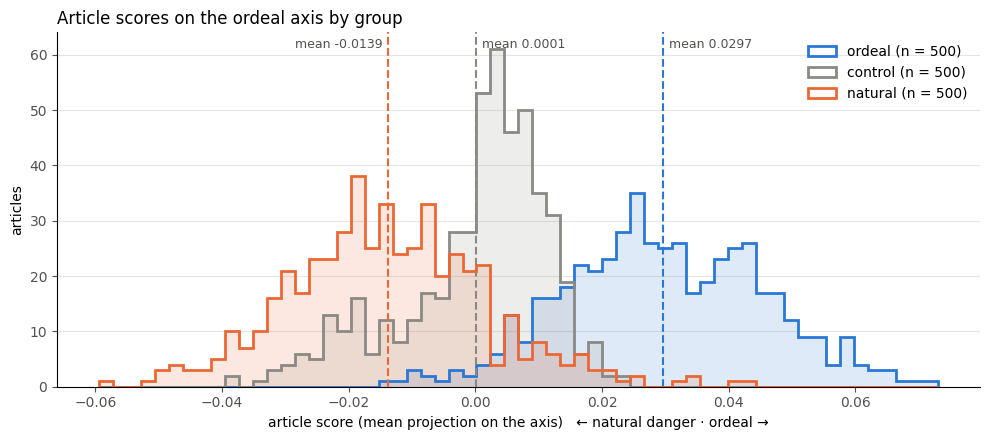

In [56]:
SCORE_COLORS = {**GROUP_COLORS, "control": "#8a8984"}
GROUP_ORDER = ["ordeal", "control", "natural"]

bins = np.histogram_bin_edges(scores["score"].dropna(), bins=60)
fig, ax = plt.subplots(figsize=(10, 4.5))
for group in GROUP_ORDER:
    s = scores.loc[scores["group"] == group, "score"].dropna()
    color = SCORE_COLORS[group]
    ax.hist(s, bins=bins, histtype="stepfilled", color=color, alpha=0.15)
    ax.hist(s, bins=bins, histtype="step", color=color, linewidth=2, label=f"{group} (n = {len(s)})")
    ax.axvline(s.mean(), color=color, linestyle="--", linewidth=1.5)
    left = group == "natural"  # label on the left of the line so it doesn't collide with control's
    ax.annotate(f"mean {s.mean():.4f}", (s.mean(), 1), xycoords=("data", "axes fraction"),
                xytext=(-4 if left else 4, -4), textcoords="offset points",
                ha="right" if left else "left", va="top", fontsize=9, color="#52514e")

ax.set_xlabel("article score (mean projection on the axis)   ← natural danger · ordeal →")
ax.set_ylabel("articles")
ax.set_title("Article scores on the ordeal axis by group", loc="left")
ax.legend(frameon=False)
style_axes(ax, grid="y")
plt.tight_layout()
plt.show()

### 3.5 Which words drive the scores

Which words move each group's score toward its pole, and which frequent words are neutral.
- **pull** = (occurrences of the word in the group × its projection) / all tokens in the group. It is the word's share of the group's mean token projection: frequent words with a moderate projection can pull more than rare words with a strong one.
- **Ordeal panel**: the words in ordeal articles with the largest positive pull. **Natural panel**: the words in natural articles with the largest negative pull, shown as positive bars.
- **Neutral**: the most frequent words across all groups with |projection| < 0.01.

The three lists are saved to `data/guardian/pole_words.csv`.

/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/3859665381.py:15: RuntimeWarning: divide by zero encountered in matmul
  "projection": kv.vectors[[kv.key_to_index[w] for w in words]] @ axis})
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/3859665381.py:15: RuntimeWarning: overflow encountered in matmul
  "projection": kv.vectors[[kv.key_to_index[w] for w in words]] @ axis})
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/3859665381.py:15: RuntimeWarning: invalid value encountered in matmul
  "projection": kv.vectors[[kv.key_to_index[w] for w in words]] @ axis})
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/3859665381.py:15: RuntimeWarning: divide by zero encountered in matmul
  "projection": kv.vectors[[kv.key_to_index[w] for w in words]] @ axis})
/var/folders/0w/smsnhm855pn3yk9bpzyggqvm0000gn/T/ipykernel_11136/3859665381.py:15: RuntimeWarning: overflow encountered in matmul
  "projection": kv.vectors[[kv.key_to_ind

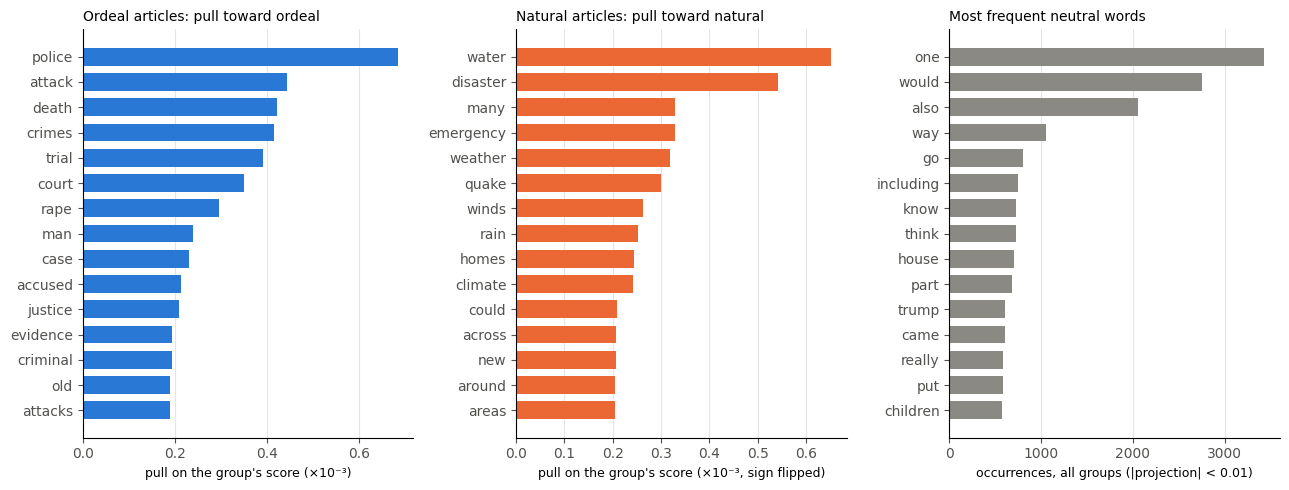

,word,count,projection,pull,list
0,police,885,0.184,0.00068,"ordeal group, toward ordeal"
1,attack,340,0.310,0.00044,"ordeal group, toward ordeal"
2,death,327,0.307,0.00042,"ordeal group, toward ordeal"
3,crimes,262,0.376,0.00041,"ordeal group, toward ordeal"
4,trial,442,0.210,0.00039,"ordeal group, toward ordeal"
5,court,731,0.114,0.00035,"ordeal group, toward ordeal"
6,rape,192,0.366,0.00030,"ordeal group, toward ordeal"
7,man,338,0.168,0.00024,"ordeal group, toward ordeal"
8,case,514,0.107,0.00023,"ordeal group, toward ordeal"
9,accused,232,0.219,0.00021,"ordeal group, toward ordeal"


In [58]:
TOP_WORDS = 15
NEUTRAL_BAND = 0.01  # |projection| below this counts as neutral

group_counts = {}
with open(DATA_DIR / "guardian" / "tokens.jsonl") as f:
    for line in f:
        art = json.loads(line)
        group_counts.setdefault(art["group"], Counter()).update(art["tokens"])


def word_table(group):
    counts = group_counts[group]
    words = list(counts)
    df = pd.DataFrame({"word": words, "count": [counts[w] for w in words],
                       "projection": kv.vectors[[kv.key_to_index[w] for w in words]] @ axis})
    df["pull"] = df["count"] * df["projection"] / sum(counts.values())
    return df


ordeal_words_df, natural_words_df = word_table("ordeal"), word_table("natural")
top_ordeal = ordeal_words_df.nlargest(TOP_WORDS, "pull")
top_natural = natural_words_df.nsmallest(TOP_WORDS, "pull")

all_counts = sum(group_counts.values(), Counter())
neutral = pd.DataFrame({"word": list(all_counts), "count": list(all_counts.values())})
neutral["projection"] = kv.vectors[[kv.key_to_index[w] for w in neutral["word"]]] @ axis
neutral = neutral[neutral["projection"].abs() < NEUTRAL_BAND].nlargest(TOP_WORDS, "count")

pole_words = pd.concat([top_ordeal.assign(list="ordeal group, toward ordeal"),
                        top_natural.assign(list="natural group, toward natural"),
                        neutral.assign(list="all groups, neutral")])
pole_words.to_csv(DATA_DIR / "guardian" / "pole_words.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
panels = [(top_ordeal["word"], top_ordeal["pull"] * 1000, GROUP_COLORS["ordeal"],
           "Ordeal articles: pull toward ordeal", "pull on the group's score (×10⁻³)"),
          (top_natural["word"], -top_natural["pull"] * 1000, GROUP_COLORS["natural"],
           "Natural articles: pull toward natural", "pull on the group's score (×10⁻³, sign flipped)"),
          (neutral["word"], neutral["count"], "#8a8984",
           "Most frequent neutral words", f"occurrences, all groups (|projection| < {NEUTRAL_BAND})")]
for ax, (words, values, color, title, xlabel) in zip(axes, panels):
    ax.barh(words.iloc[::-1], values.iloc[::-1], color=color, height=0.7)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel(xlabel, fontsize=9)
    style_axes(ax, grid="x")
plt.tight_layout()
plt.show()

display(pole_words.round({"projection": 3, "pull": 5}).reset_index(drop=True))